# Imports:

In [68]:
import pandas as pd
import requests
import numpy as np
from datasets import Dataset
from PIL import Image
from datasets import load_dataset, Image as HFImage
import base64
from io import BytesIO
from PIL import Image
from IPython.display import HTML
import torch
from torchvision import models
from datasets import load_dataset, concatenate_datasets
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, top_k_accuracy_score, classification_report

# Example Instance

In [69]:
ds = load_dataset("moondream/geoguessr-countries-finetune", split="train+test")
# ds = ds.class_encode_column("country")                  # strings → integer IDs

sample = ds[0]
display(sample["image"])  
print("Country:", sample["country"])

{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\x08\x06\x06\x07\x06\x05\x08\x07\x07\x07\t\t\x08\n\x0c\x14\r\x0c\x0b\x0b\x0c\x19\x12\x13\x0f\x14\x1d\x1a\x1f\x1e\x1d\x1a\x1c\x1c $.\' ",#\x1c\x1c(7),01444\x1f\'9=82<.342\xff\xdb\x00C\x01\t\t\t\x0c\x0b\x0c\x18\r\r\x182!\x1c!22222222222222222222222222222222222222222222222222\xff\xc0\x00\x11\x08\x02\x96\x06\x00\x03\x01"\x00\x02\x11\x01\x03\x11\x01\xff\xc4\x00\x1f\x00\x00\x01\x05\x01\x01\x01\x01\x01\x01\x00\x00\x00\x00\x00\x00\x00\x00\x01\x02\x03\x04\x05\x06\x07\x08\t\n\x0b\xff\xc4\x00\xb5\x10\x00\x02\x01\x03\x03\x02\x04\x03\x05\x05\x04\x04\x00\x00\x01}\x01\x02\x03\x00\x04\x11\x05\x12!1A\x06\x13Qa\x07"q\x142\x81\x91\xa1\x08#B\xb1\xc1\x15R\xd1\xf0$3br\x82\t\n\x16\x17\x18\x19\x1a%&\'()*456789:CDEFGHIJSTUVWXYZcdefghijstuvwxyz\x83\x84\x85\x86\x87\x88\x89\x8a\x92\x93\x94\x95\x96\x97\x98\x99\x9a\xa2\xa3\xa4\xa5\xa6\xa7\xa8\xa9\xaa\xb2\xb3\xb4\xb5\xb6\xb7\xb8\xb9\xba\xc2\xc3\xc4\xc5\xc6\xc7\xc8\xc9\xc

Country: Japan


,image,country
0,,Japan
1,,South Africa
2,,Australia
3,,Chile
4,,Australia

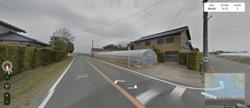
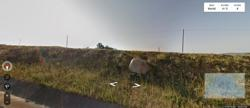
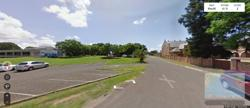
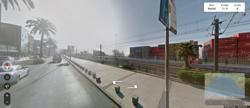
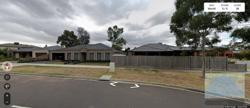

In [70]:
def head(ds, n=5, width=250):
    df = ds.select(range(n)).to_pandas()

    def to_img_tag(img):
        im = Image.open(BytesIO(img["bytes"]))
        im.thumbnail((width, width))
        buf = BytesIO()
        im.save(buf, format="JPEG")
        b64 = base64.b64encode(buf.getvalue()).decode()
        return f'<img src="data:image/jpeg;base64,{b64}" width="{width}">'

    df["image"] = df["image"].apply(to_img_tag)
    return HTML(df.to_html(escape=False))

head(ds)

In [71]:
ds.to_pandas()["country"].value_counts()

country
Japan             2711
France            2523
United Kingdom    1759
Brazil            1643
Russia            1241
Australia         1212
Canada             974
South Africa       831
Spain              758
Finland            739
Thailand           668
Mexico             637
Poland             608
Italy              556
Sweden             510
Singapore          497
Germany            497
Argentina          484
Norway             480
Netherlands        410
New Zealand        393
Taiwan             386
Malaysia           296
Romania            246
Austria            243
Israel             229
Chile              226
Ireland            208
Indonesia          202
Peru               191
Turkey             188
Czechia            183
Greece             177
Colombia           175
South Korea        170
Portugal           169
Philippines        155
Bulgaria           153
Belgium            151
Denmark            138
Switzerland        124
Hungary            119
India              115
Bot

# Methods
1. Run the images through a pretrained CNN or CLIP once to get embeddings
2. Train your logistic regression, SVM, and gradient boosting models on those embeddings.
3. Fine-tune the CNN itself as a fourth, “deep learning” model to compare against.

In [72]:
from io import BytesIO
from PIL import Image

def get_img(sample):
    img = sample["image"]
    if isinstance(img, dict):          # decode=False → raw bytes
        img = Image.open(BytesIO(img["bytes"]))
    return img.convert("RGB")

In [73]:
weights = models.ResNet50_Weights.DEFAULT
cnn = models.resnet50(weights=weights) # embedding models
cnn.fc = torch.nn.Identity()          # drop classifier → outputs 2048-dim features
cnn.eval()
preprocess = weights.transforms()

@torch.no_grad()
def cnn_embed(samples):
    batch = torch.stack([preprocess(get_img(s)) for s in samples])
    return cnn(batch).numpy()

X = cnn_embed([ds[i] for i in range(8)])
print(X.shape)   # (8, 2048)

(8, 2048)


Next Meeting 
1. Determine Embedding model
2. Assign models
   1. 2 models each
3. Fine tune final model/ test model (ensemble?)

# Nina Exploration

In [74]:
# Use GPU if availble
device = "cuda" if torch.cuda.is_available() else "cpu"
cnn.to(device).eval()

@torch.no_grad()
# Embed models 
def embed_split(data, bs=64):
    X, y = [],[]
    for i in range(0, len(data), bs):
        rows = data.select(range(i, min(i + bs, (len(data)))))
        for r in rows:
            batch = torch.stack([preprocess(get_img(r))]).to(device)
        X.append(cnn(batch).cpu().numpy())
        y.extend(rows["country"])
    return np.concatenate(X), np.array(y)


In [75]:
ds

Dataset({
    features: ['image', 'country'],
    num_rows: 25400
})

In [76]:
df = ds.select_columns(["country"]).to_pandas() 
counts = df["country"].value_counts()
df = df[df["country"].isin(counts[counts > 100].index)]
ds = ds.select(df.index)
ds = ds.class_encode_column("country")

split = ds.train_test_split(test_size=0.2, seed=42, stratify_by_column="country")

print(split)

Casting to class labels: 100%|██████████| 24477/24477 [00:06<00:00, 3574.68 examples/s]


DatasetDict({
    train: Dataset({
        features: ['image', 'country'],
        num_rows: 19581
    })
    test: Dataset({
        features: ['image', 'country'],
        num_rows: 4896
    })
})


In [77]:
ds.to_pandas()["country"].value_counts()

country
22    2711
13    2523
43    1759
5     1643
33    1241
1     1212
7      974
35     831
37     758
12     739
41     668
24     637
30     608
21     556
38     510
34     497
14     497
0      484
27     480
25     410
26     393
40     386
23     296
32     246
2      243
20     229
8      226
19     208
18     202
28     191
42     188
10     183
15     177
9      175
36     170
31     169
29     155
6      153
3      151
11     138
39     124
16     119
17     115
4      102
Name: count, dtype: int64

In [79]:
X_train, y_train = embed_split(split["train"])
X_test, y_test = embed_split(split["test"])

KeyboardInterrupt: 